In [1]:
import os
import sys
import argparse
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score
from sklearn.datasets import fetch_openml

# Classifier Heads to test
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

from src.datasets import DatasetManager
from src.pqc_encoder import PQCEncoder
from src.meta_rl_es import EvolutionStrategies
from src.utils_metrics import compute_metrics

def load_openml_dataset(data_id):
    print(f"\nFetching OpenML dataset ID {data_id} directly from OpenML... (This may take a few seconds)")
    data = fetch_openml(data_id=data_id, as_frame=True, parser='auto')
    df = data.frame
    
    target_col = data.target.name if hasattr(data, 'target') and data.target is not None else df.columns[-1]
    
    # Convert non-target category/object columns to float if possible, or label encode them
    for col in df.columns:
        if col != target_col:
            if df[col].dtype.name in ['category', 'object']:
                converted = pd.to_numeric(df[col], errors='coerce')
                if converted.isnull().sum() < 0.5 * len(df):
                    df[col] = converted.fillna(0)
                else:
                    df[col] = df[col].astype('category').cat.codes
                    
    df_numeric = df.select_dtypes(include=[np.number])
    if target_col in df_numeric.columns:
        X = df_numeric.drop(columns=[target_col]).values
    else:
        X = df_numeric.values
        
    y_raw = df[target_col].values
    
    # Map label mapping: identify minority class as anomaly (1) and majority as normal (0)
    unique_classes, counts = np.unique(y_raw, return_counts=True)
    majority_class = unique_classes[np.argmax(counts)]
    y = (y_raw != majority_class).astype(int)
    
    print(f"Successfully loaded OpenML ID {data_id}:")
    print(f"  Shape: {X.shape[0]} samples, {X.shape[1]} features")
    print(f"  Class Distribution: Normal (0): {np.sum(y == 0)}, Anomaly (1): {np.sum(y == 1)}")
    
    return X, y

def plot_and_save_comparison(results_df, plot_path="images/classifier_comparison.png"):
    plt.figure(figsize=(12, 6))
    
    # Melt the dataframe for Seaborn barplot plotting
    melted_df = pd.melt(results_df, id_vars=['Classifier'], value_vars=['F1-Score (0.5)', 'F1-Score (Tuned)', 'ROC AUC'],
                        var_name='Metric', value_name='Score')
    
    sns.barplot(x='Classifier', y='Score', hue='Metric', data=melted_df, palette='muted')
    
    plt.ylim(0, 1.0)
    plt.title("Comparison of Few-Shot Head Classifiers (Adapted on 10 Support Samples)")
    plt.xlabel("Classifier Head Type")
    plt.ylabel("Performance Score")
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    
    os.makedirs(os.path.dirname(plot_path), exist_ok=True)
    plt.savefig(plot_path)
    plt.close()
    print(f"\nComparison bar chart successfully saved to '{plot_path}'")

def run_unseen_testing(weights_file="meta_pqc_weights.npy", dataset_id=182):
    # Step 1: Ensure weights exist
    if not os.path.exists(weights_file):
        print(f"Error: Weights file '{weights_file}' not found.")
        return
        
    # Step 2: Load trained parameters
    print(f"Loading meta-trained quantum weights from '{weights_file}'...")
    meta_params = np.load(weights_file)
    n_layers, n_qubits, _ = meta_params.shape
    print(f"Detected PQC architecture: Qubits={n_qubits}, Layers={n_layers}")
    
    # Step 3: Load unseen dataset from OpenML
    X_new, y_new = load_openml_dataset(data_id=dataset_id)
    
    # Step 4: Preprocess (Standardize + PCA + Zero-padding to n_qubits)
    print("Preprocessing new data (Scaling and PCA mapping)...")
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_new)
    
    n_components = min(n_qubits, X_scaled.shape[1])
    pca = PCA(n_components=n_components)
    X_pca = pca.fit_transform(X_scaled)
    
    if X_pca.shape[1] < n_qubits:
        padding = np.zeros((X_pca.shape[0], n_qubits - X_pca.shape[1]))
        X_pca = np.concatenate([X_pca, padding], axis=1)
        
    # Normalize features to [-pi, pi] for angle encoding
    min_val, max_val = np.min(X_pca, axis=0), np.max(X_pca, axis=0)
    X_normalized = 2 * np.pi * (X_pca - min_val) / (max_val - min_val + 1e-8) - np.pi
    
    # Step 5: Feed data through the frozen meta-trained PQC feature extractor
    print("Extracting quantum features via the Parameterized Quantum Circuit (PQC)...")
    pqc = PQCEncoder(n_qubits=n_qubits, n_layers=n_layers)
    pqc.set_params(meta_params)
    X_quantum = pqc.forward(X_normalized)
    
    # Step 6: Sample 5 normal and 5 anomaly samples for the support set
    normal_idx = np.where(y_new == 0)[0]
    anomaly_idx = np.where(y_new == 1)[0]
    
    k_support = min(5, len(normal_idx), len(anomaly_idx))
    np.random.seed(42) # Fixed seed to keep comparison fair
    support_normal = np.random.choice(normal_idx, k_support, replace=False)
    support_anomaly = np.random.choice(anomaly_idx, k_support, replace=False)
    support_indices = np.concatenate([support_normal, support_anomaly])
    query_indices = np.setdiff1d(np.arange(len(y_new)), support_indices)
    
    X_support = X_quantum[support_indices]
    y_support = y_new[support_indices]
    X_query = X_quantum[query_indices]
    y_query = y_new[query_indices]
    
    # Step 7: Benchmark 4 different classifier heads
    print("Evaluating different few-shot classification heads...")
    
    classifiers = {
        "Logistic Regression (Linear)": LogisticRegression(class_weight='balanced', max_iter=1000),
        "SVM (RBF Kernel)": SVC(probability=True, class_weight='balanced'),
        "Random Forest (100 Trees)": RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42),
        "MLP Classifier (Neural Net)": MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=1000, random_state=42)
    }
    
    results = []
    
    for name, clf in classifiers.items():
        # Fit on support set (10 samples)
        clf.fit(X_support, y_support)
        
        # Predict on query set
        if hasattr(clf, "predict_proba"):
            y_prob = clf.predict_proba(X_query)[:, 1]
            y_prob_support = clf.predict_proba(X_support)[:, 1]
        else:
            y_prob = clf.decision_function(X_query)
            y_prob = (y_prob - y_prob.min()) / (y_prob.max() - y_prob.min() + 1e-8)
            y_prob_support = clf.decision_function(X_support)
            y_prob_support = (y_prob_support - y_prob_support.min()) / (y_prob_support.max() - y_prob_support.min() + 1e-8)
            
        # Default F1 (threshold 0.5)
        y_pred_def = (y_prob >= 0.5).astype(int)
        f1_def = f1_score(y_query, y_pred_def, zero_division=0)
        
        # Tuned F1 (threshold search on support set)
        best_thresholds = []
        best_support_f1 = -1.0
        for thresh in np.linspace(0.01, 0.99, 100):
            y_pred_s = (y_prob_support >= thresh).astype(int)
            f1_s = f1_score(y_support, y_pred_s, zero_division=0)
            if f1_s > best_support_f1:
                best_support_f1 = f1_s
                best_thresholds = [thresh]
            elif f1_s == best_support_f1:
                best_thresholds.append(thresh)
        best_thresh = np.mean(best_thresholds) if best_thresholds else 0.5
        
        y_pred_tuned = (y_prob >= best_thresh).astype(int)
        f1_tuned = f1_score(y_query, y_pred_tuned, zero_division=0)
        
        acc = accuracy_score(y_query, y_pred_tuned)
        auc = roc_auc_score(y_query, y_prob)
        
        results.append({
            "Classifier": name,
            "Accuracy": acc,
            "ROC AUC": auc,
            "F1-Score (0.5)": f1_def,
            "F1-Score (Tuned)": f1_tuned,
            "Tuned Thresh": best_thresh
        })
        
    df_results = pd.DataFrame(results)
    
    # Step 8: Print Comparison Table
    print("\n" + "="*80)
    print("COMPARISON OF CLASSIFICATION HEADS ON UNSEEN DATA (5-SHOT)")
    print("="*80)
    print(df_results.to_string(index=False))
    print("="*80)
    
    # Save results to CSV for logging
    os.makedirs("reports/results", exist_ok=True)
    df_results.to_csv("reports/results/head_classifier_comparison.csv", index=False)
    
    # Step 9: Plot and save comparison graph
    plot_path = f"images/classifier_comparison_{weights_file.replace('.npy', '')}_{dataset_id}.png"
    plot_and_save_comparison(df_results, plot_path)

if __name__ == "__main__":
    parser = argparse.ArgumentParser(description="Test Meta-Trained Quantum Weights on Unseen Data")
    parser.add_argument("--weights", type=str, default="quantum_brain_weights.npy",
                        help="Numpy weights file to load (e.g. meta_pqc_weights.npy or quantum_brain_weights.npy)")
    parser.add_argument("--dataset", type=int, default=182,
                        help="OpenML dataset ID (e.g. 37 for Diabetes, 1481 for CTG)")
    
    args = parser.parse_args()
    run_unseen_testing(weights_file=args.weights, dataset_id=args.dataset)


usage: ipykernel_launcher.py [-h] [--weights WEIGHTS] [--dataset DATASET]
ipykernel_launcher.py: error: unrecognized arguments: --f=/Users/pushkar/Library/Jupyter/runtime/kernel-v340c0511425eb3a4118b2e48734cc2172f86e25da.json


SystemExit: 2

/Users/pushkar/Documents/Practicum/qml_env/lib/python3.14/site-packages/IPython/core/interactiveshell.py:3755: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


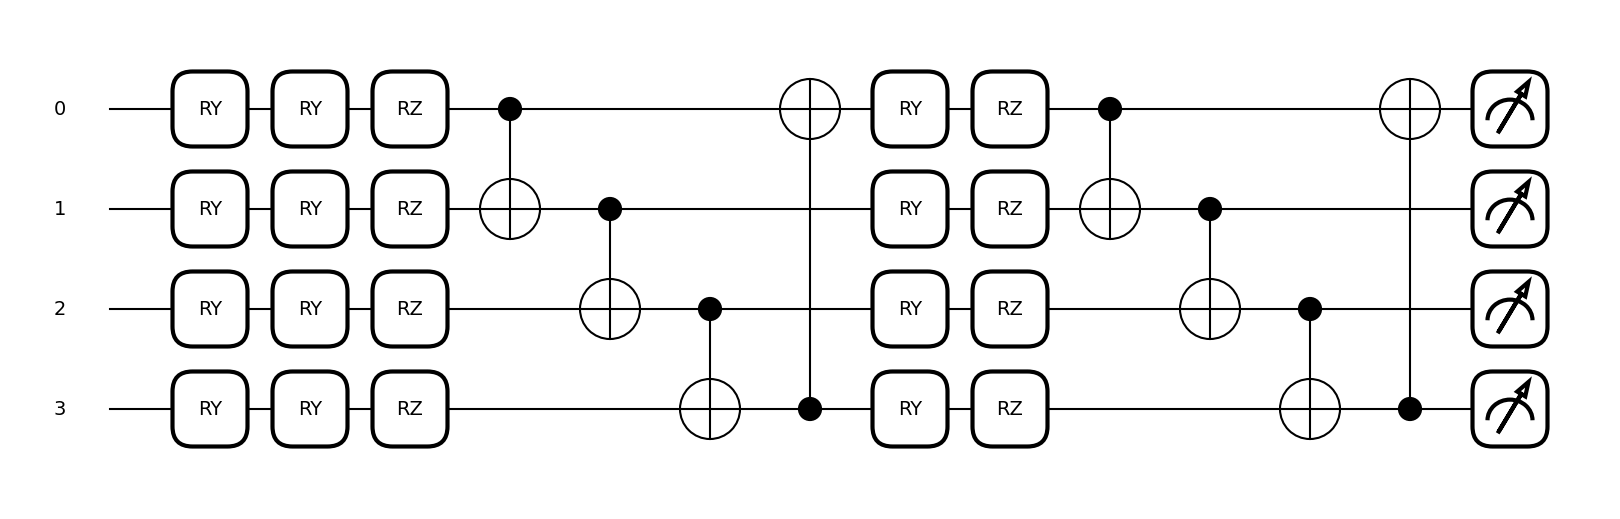

In [2]:
import pennylane as qml
import numpy as np
import matplotlib.pyplot as plt

n_qubits = 4
n_layers = 2

dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev)
def pqc(x, weights):
    # Angle encoding
    for i in range(n_qubits):
        qml.RY(x[i], wires=i)
    # Variational layers
    for l in range(n_layers):
        for i in range(n_qubits):
            qml.RY(weights[l, i, 0], wires=i)
            qml.RZ(weights[l, i, 1], wires=i)
        # CNOT ring
        for i in range(n_qubits):
            qml.CNOT(wires=[i, (i+1) % n_qubits])
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

# dummy inputs just for drawing
x_demo = np.zeros(n_qubits)
w_demo = np.zeros((n_layers, n_qubits, 2))

fig, ax = qml.draw_mpl(pqc)(x_demo, w_demo)
fig.savefig("pqc_circuit.png", bbox_inches="tight", dpi=300)